In [60]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [61]:
# Set random seed for reproducibility
np.random.seed(42)

# Number of students
n = 1000

# Generate student dataset
data = {

    # 1. Student Identification
    "Student_ID": [f"STU{i:03d}" for i in range(1, n + 1)],

    # 2–10. Numerical Features
    "Age": np.random.randint(17, 26, n),

    "Attendance": np.round(
        np.random.uniform(40, 100, n), 2
    ),

    "Study_Hours": np.round(
        np.random.uniform(0, 10, n), 2
    ),

    "Previous_Marks": np.round(
        np.random.uniform(20, 100, n), 2
    ),

    "Assignment_Score": np.round(
        np.random.uniform(20, 100, n), 2
    ),

    "Internal_Marks": np.round(
        np.random.uniform(20, 100, n), 2
    ),

    "Quiz_Average": np.round(
        np.random.uniform(20, 100, n), 2
    ),

    "Practical_Score": np.round(
        np.random.uniform(20, 100, n), 2
    ),

    "Learning_Hours": np.round(
        np.random.uniform(0, 20, n), 2
    ),

    # 11–14. Categorical Features
    "Class_Participation": np.random.choice(
        ["Low", "Medium", "High"],
        n,
        p=[0.20, 0.50, 0.30]
    ),

    "Assignment_Submission": np.random.choice(
        ["On Time", "Late", "Not Submitted"],
        n,
        p=[0.65, 0.25, 0.10]
    ),

    "Internet_Access": np.random.choice(
        ["Yes", "No"],
        n,
        p=[0.85, 0.15]
    ),

    "Extracurricular_Activities": np.random.choice(
        ["Yes", "No"],
        n,
        p=[0.60, 0.40]
    )
}

# Create numerical representations of categorical features
participation_score = pd.Series(
    data["Class_Participation"]
).map({
    "Low": 40,
    "Medium": 70,
    "High": 100
}).to_numpy()

submission_score = pd.Series(
    data["Assignment_Submission"]
).map({
    "Not Submitted": 20,
    "Late": 60,
    "On Time": 100
}).to_numpy()

# Calculate synthetic academic performance score
performance_score = (
    0.15 * data["Attendance"] +
    0.15 * data["Previous_Marks"] +
    0.12 * data["Assignment_Score"] +
    0.18 * data["Internal_Marks"] +
    0.12 * data["Quiz_Average"] +
    0.12 * data["Practical_Score"] +
    0.08 * (data["Study_Hours"] * 10) +
    0.04 * (data["Learning_Hours"] * 5) +
    0.02 * participation_score +
    0.02 * submission_score +
    np.random.normal(0, 4, n)
)

# Keep scores within 0–100
performance_score = np.clip(
    performance_score, 0, 100
)

# 15. Generate target variable
data["Performance_Category"] = pd.cut(
    performance_score,
    bins=[-np.inf, 45, 65, 80, np.inf],
    labels=[
        "At Risk",
        "Average",
        "Good",
        "Excellent"
    ]
)

# Create final DataFrame
df = pd.DataFrame(data)

print("Synthetic dataset generated successfully!")

Synthetic dataset generated successfully!


In [62]:
# Display first 10 student records
display(df.head(10))

,Student_ID,Age,Attendance,Study_Hours,Previous_Marks,Assignment_Score,Internal_Marks,Quiz_Average,Practical_Score,Learning_Hours,Class_Participation,Assignment_Submission,Internet_Access,Extracurricular_Activities,Performance_Category
0,STU001,23,53.86,6.89,46.53,60.19,36.33,36.34,81.38,1.08,Medium,On Time,Yes,Yes,Average
1,STU002,20,80.31,8.73,88.40,78.52,57.52,70.14,36.47,9.14,Medium,On Time,Yes,Yes,Good
2,STU003,24,41.18,6.36,36.57,96.65,84.08,48.70,45.73,10.99,Low,On Time,Yes,Yes,Average
3,STU004,21,46.25,7.61,25.69,37.64,34.41,99.65,57.24,17.76,Medium,Not Submitted,Yes,Yes,Average
4,STU005,23,87.99,1.60,25.52,90.89,28.79,58.41,95.46,2.09,High,On Time,Yes,No,Average
5,STU006,19,50.71,4.62,95.26,94.74,90.69,58.87,94.54,16.45,Medium,Late,Yes,Yes,Good
6,STU007,23,79.16,0.09,60.55,93.31,47.43,65.27,36.55,4.20,High,Late,Yes,Yes,Average
7,STU008,24,54.29,2.47,52.75,70.83,74.71,93.34,48.66,7.88,Medium,Late,Yes,Yes,Good
8,STU009,21,45.97,7.26,84.87,70.39,22.03,84.07,31.95,6.33,Medium,On Time,Yes,Yes,Average
9,STU010,20,54.59,9.92,86.87,52.26,75.20,56.09,60.80,8.00,Low,On Time,Yes,Yes,Good


In [63]:
# Check dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 15)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   Student_ID                  1000 non-null   object  
 1   Age                         1000 non-null   int64   
 2   Attendance                  1000 non-null   float64 
 3   Study_Hours                 1000 non-null   float64 
 4   Previous_Marks              1000 non-null   float64 
 5   Assignment_Score            1000 non-null   float64 
 6   Internal_Marks              1000 non-null   float64 
 7   Quiz_Average                1000 non-null   float64 
 8   Practical_Score             1000 non-null   float64 
 9   Learning_Hours              1000 non-null   float64 
 10  Class_Participation         1000 non-null   object  
 11  Assignment_Submission       1000 non-null   object  
 12  Internet_Access             1

In [64]:
# Check missing values in each column

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Student_ID                    0
Age                           0
Attendance                    0
Study_Hours                   0
Previous_Marks                0
Assignment_Score              0
Internal_Marks                0
Quiz_Average                  0
Practical_Score               0
Learning_Hours                0
Class_Participation           0
Assignment_Submission         0
Internet_Access               0
Extracurricular_Activities    0
Performance_Category          0
dtype: int64

Total Missing Values: 0


In [65]:
# Check duplicate records

print("Duplicate Rows:", df.duplicated().sum())
print("Unique Student IDs:", df["Student_ID"].nunique())

Duplicate Rows: 0
Unique Student IDs: 1000


In [66]:
# Count students in each performance category

print(df["Performance_Category"].value_counts())

# Percentage distribution
print("\nPercentage Distribution:")
print(
    df["Performance_Category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Performance_Category
Average      644
Good         299
At Risk       41
Excellent     16
Name: count, dtype: int64

Percentage Distribution:
Performance_Category
Average      64.4
Good         29.9
At Risk       4.1
Excellent     1.6
Name: proportion, dtype: float64


In [67]:
# Export dataset to CSV

df.to_csv("student_performance_dataset.csv", index=False)
print("Dataset exported successfully!")

from google.colab import files

files.download("student_performance_dataset.csv")

Dataset exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
# Dataset overview

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 10 Records:")
display(df.head(10))

Dataset Shape: (1000, 15)

Column Names:
['Student_ID', 'Age', 'Attendance', 'Study_Hours', 'Previous_Marks', 'Assignment_Score', 'Internal_Marks', 'Quiz_Average', 'Practical_Score', 'Learning_Hours', 'Class_Participation', 'Assignment_Submission', 'Internet_Access', 'Extracurricular_Activities', 'Performance_Category']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   Student_ID                  1000 non-null   object  
 1   Age                         1000 non-null   int64   
 2   Attendance                  1000 non-null   float64 
 3   Study_Hours                 1000 non-null   float64 
 4   Previous_Marks              1000 non-null   float64 
 5   Assignment_Score            1000 non-null   float64 
 6   Internal_Marks              1000 non-null   float64 
 7   Quiz_Average           

,Student_ID,Age,Attendance,Study_Hours,Previous_Marks,Assignment_Score,Internal_Marks,Quiz_Average,Practical_Score,Learning_Hours,Class_Participation,Assignment_Submission,Internet_Access,Extracurricular_Activities,Performance_Category
0,STU001,23,53.86,6.89,46.53,60.19,36.33,36.34,81.38,1.08,Medium,On Time,Yes,Yes,Average
1,STU002,20,80.31,8.73,88.40,78.52,57.52,70.14,36.47,9.14,Medium,On Time,Yes,Yes,Good
2,STU003,24,41.18,6.36,36.57,96.65,84.08,48.70,45.73,10.99,Low,On Time,Yes,Yes,Average
3,STU004,21,46.25,7.61,25.69,37.64,34.41,99.65,57.24,17.76,Medium,Not Submitted,Yes,Yes,Average
4,STU005,23,87.99,1.60,25.52,90.89,28.79,58.41,95.46,2.09,High,On Time,Yes,No,Average
5,STU006,19,50.71,4.62,95.26,94.74,90.69,58.87,94.54,16.45,Medium,Late,Yes,Yes,Good
6,STU007,23,79.16,0.09,60.55,93.31,47.43,65.27,36.55,4.20,High,Late,Yes,Yes,Average
7,STU008,24,54.29,2.47,52.75,70.83,74.71,93.34,48.66,7.88,Medium,Late,Yes,Yes,Good
8,STU009,21,45.97,7.26,84.87,70.39,22.03,84.07,31.95,6.33,Medium,On Time,Yes,Yes,Average
9,STU010,20,54.59,9.92,86.87,52.26,75.20,56.09,60.80,8.00,Low,On Time,Yes,Yes,Good


In [69]:
# Statistical summary of numerical features
df.describe()

,Age,Attendance,Study_Hours,Previous_Marks,Assignment_Score,Internal_Marks,Quiz_Average,Practical_Score,Learning_Hours
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000
mean,20.898000,70.207680,4.977110,59.590180,59.360790,59.881940,59.641260,58.68844,9.659540
std,2.603916,17.579614,2.890855,22.883592,23.041094,23.082009,23.232093,22.76395,5.681104
min,17.000000,40.300000,0.000000,20.000000,20.000000,20.080000,20.110000,20.02000,0.000000
25%,19.000000,54.280000,2.597500,39.852500,39.247500,40.220000,39.472500,39.18500,4.712500
50%,21.000000,70.940000,4.950000,59.350000,59.420000,58.835000,59.330000,58.64500,9.365000
75%,23.000000,85.492500,7.515000,79.115000,78.777500,79.330000,80.590000,77.13500,14.380000
max,25.000000,99.960000,9.980000,99.960000,99.820000,99.950000,99.960000,99.91000,19.920000


In [70]:
# Categorical feature analysis

categorical_columns = [
    "Class_Participation",
    "Assignment_Submission",
    "Internet_Access",
    "Extracurricular_Activities",
    "Performance_Category"
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Class_Participation
Class_Participation
Medium    527
High      291
Low       182
Name: count, dtype: int64

 Assignment_Submission
Assignment_Submission
On Time          650
Late             249
Not Submitted    101
Name: count, dtype: int64

 Internet_Access
Internet_Access
Yes    834
No     166
Name: count, dtype: int64

 Extracurricular_Activities
Extracurricular_Activities
Yes    603
No     397
Name: count, dtype: int64

 Performance_Category
Performance_Category
Average      644
Good         299
At Risk       41
Excellent     16
Name: count, dtype: int64


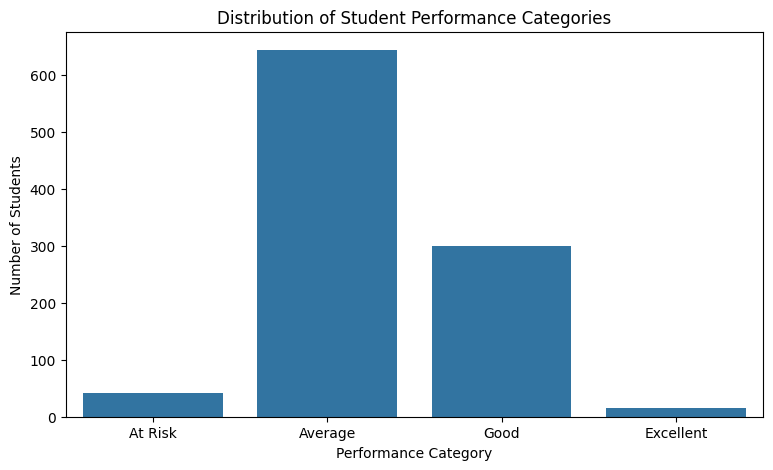

In [71]:
# Performance category distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Performance_Category",
    order=["At Risk", "Average", "Good", "Excellent"]
)

plt.title("Distribution of Student Performance Categories")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.show()

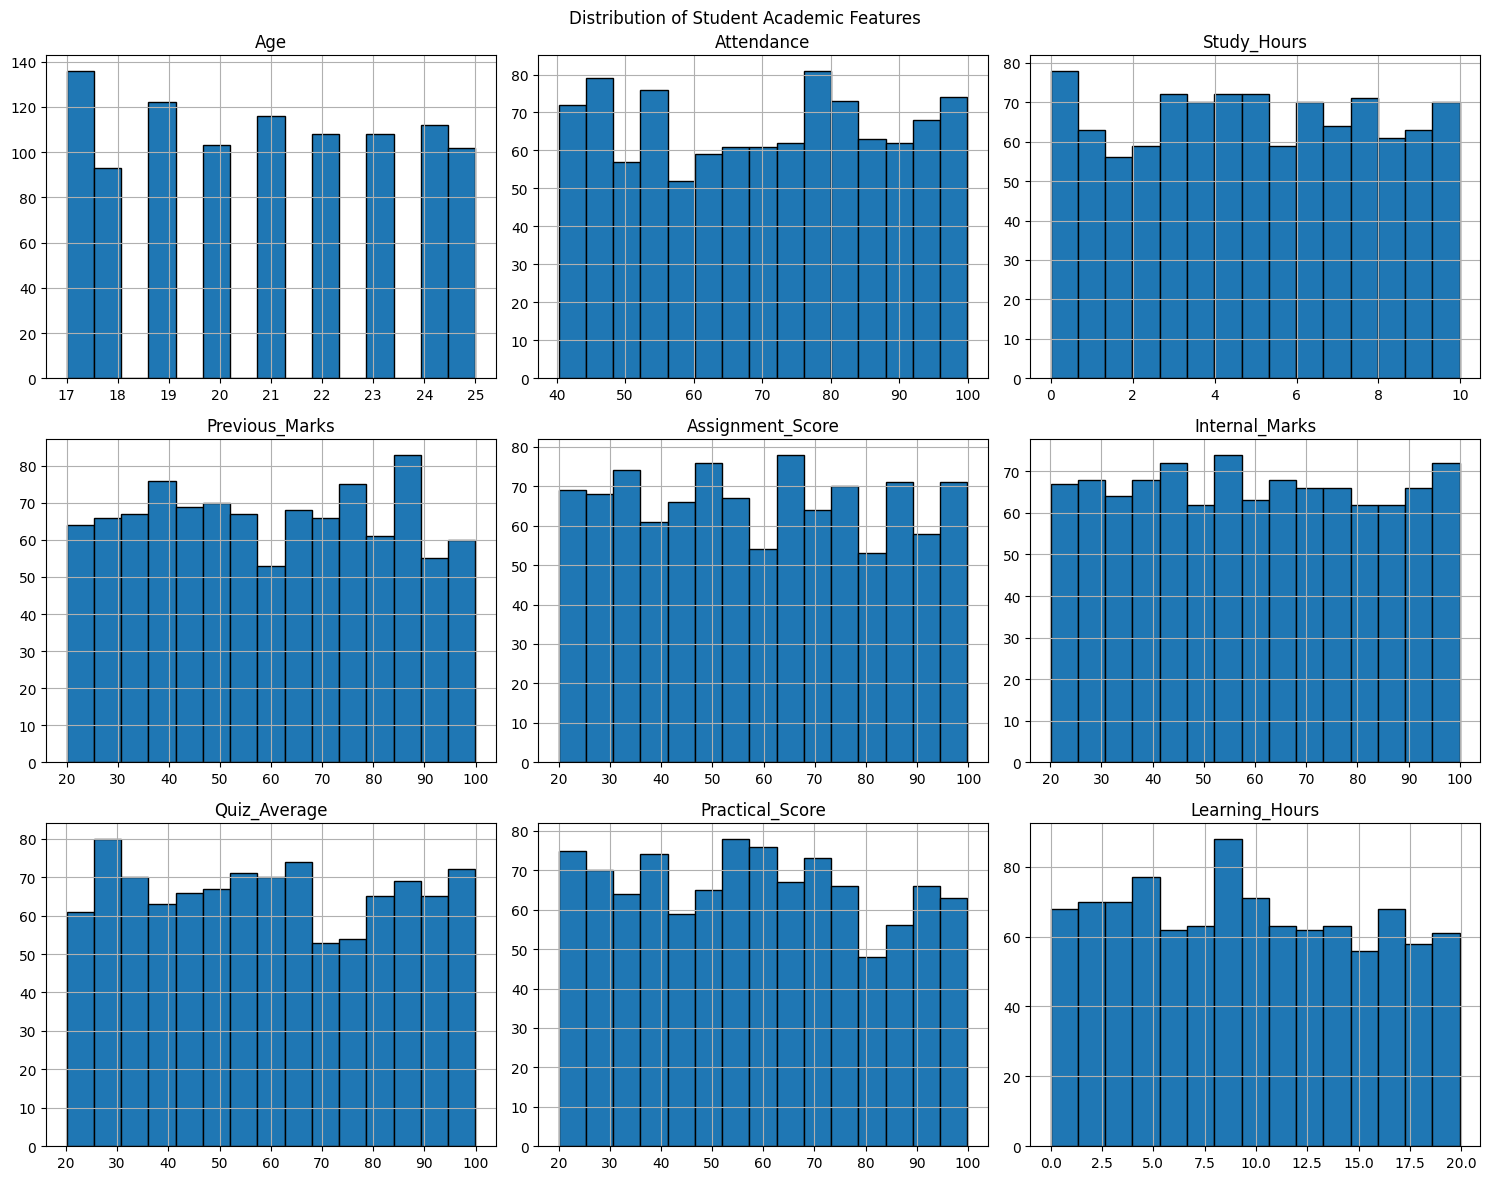

In [72]:
# Numerical feature distributions

numerical_columns = [
    "Age",
    "Attendance",
    "Study_Hours",
    "Previous_Marks",
    "Assignment_Score",
    "Internal_Marks",
    "Quiz_Average",
    "Practical_Score",
    "Learning_Hours"
]

df[numerical_columns].hist(
    figsize=(15, 12),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Student Academic Features")
plt.tight_layout()
plt.show()

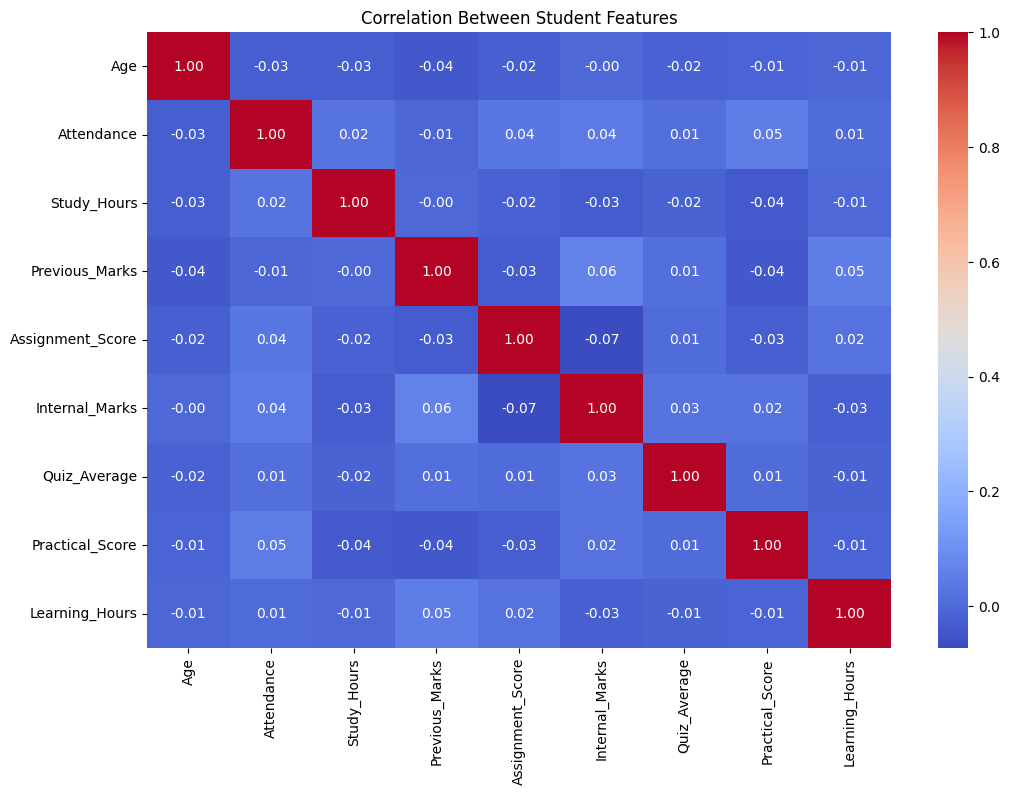

In [73]:
# Correlation heatmap

plt.figure(figsize=(12, 8))
correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Student Features")
plt.show()

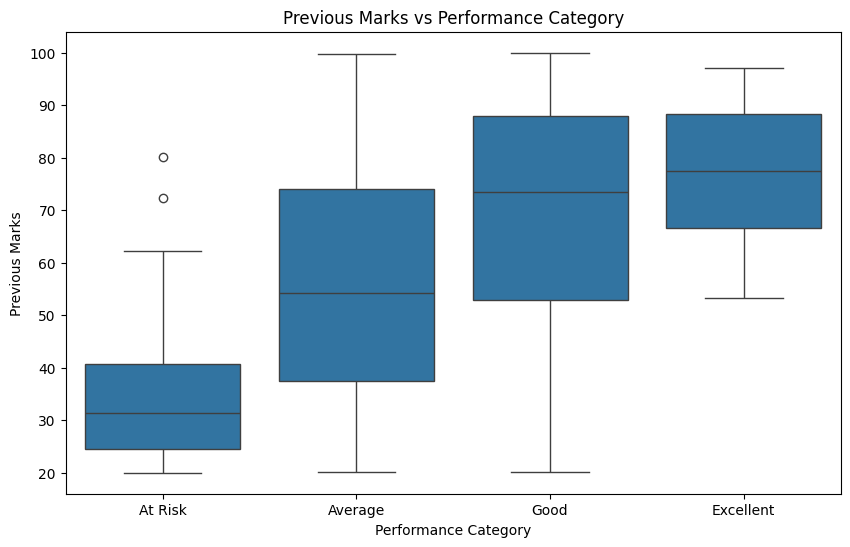

In [74]:
# Compare academic scores across performance categories

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Performance_Category",
    y="Previous_Marks",
    order=["At Risk", "Average", "Good", "Excellent"]
)

plt.title("Previous Marks vs Performance Category")
plt.xlabel("Performance Category")
plt.ylabel("Previous Marks")

plt.show()

In [75]:
# Import preprocessing libraries

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [76]:
# Remove Student_ID from dataset

df_ml = df.drop(columns=["Student_ID"])
print("Student_ID removed successfully!")

print("Original Dataset Shape:", df.shape)
print("ML Dataset Shape:", df_ml.shape)

Student_ID removed successfully!
Original Dataset Shape: (1000, 15)
ML Dataset Shape: (1000, 14)


In [77]:
# Check missing values

print("Missing Values:")
print(df_ml.isnull().sum())

print("\nTotal Missing Values:", df_ml.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:", df_ml.duplicated().sum())

Missing Values:
Age                           0
Attendance                    0
Study_Hours                   0
Previous_Marks                0
Assignment_Score              0
Internal_Marks                0
Quiz_Average                  0
Practical_Score               0
Learning_Hours                0
Class_Participation           0
Assignment_Submission         0
Internet_Access               0
Extracurricular_Activities    0
Performance_Category          0
dtype: int64

Total Missing Values: 0

Duplicate Records: 0


In [78]:
# Separate features and target

X = df_ml.drop(columns=["Performance_Category"])
y = df_ml["Performance_Category"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nTarget Categories:")
print(y.value_counts())

Input Features Shape: (1000, 13)
Target Variable Shape: (1000,)

Target Categories:
Performance_Category
Average      644
Good         299
At Risk       41
Excellent     16
Name: count, dtype: int64


In [79]:
# Identify numerical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Attendance', 'Study_Hours', 'Previous_Marks', 'Assignment_Score', 'Internal_Marks', 'Quiz_Average', 'Practical_Score', 'Learning_Hours']

Categorical Features:
['Class_Participation', 'Assignment_Submission', 'Internet_Access', 'Extracurricular_Activities']


In [80]:
# Numerical preprocessing

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [81]:
# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (800, 13)
Testing Data: (200, 13)
Training Target: (800,)
Testing Target: (200,)


In [82]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data
X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:",
      X_train_processed.shape)

print("Testing Data After Preprocessing:",
      X_test_processed.shape)

Training Data After Preprocessing: (800, 19)
Testing Data After Preprocessing: (200, 19)


In [106]:
# Check processed data

print("Training Data Shape:", X_train_processed.shape)
print("Testing Data Shape:", X_test_processed.shape)

# Check missing values in training data
if hasattr(X_train_processed, "toarray"):
    train_data = X_train_processed.toarray()
else:
    train_data = X_train_processed

# Check missing values in testing data
if hasattr(X_test_processed, "toarray"):
    test_data = X_test_processed.toarray()
else:
    test_data = X_test_processed

print("\nMissing Values in Training Data:",
      np.isnan(train_data).sum())

print("Missing Values in Testing Data:",
      np.isnan(test_data).sum())

Training Data Shape: (800, 19)
Testing Data Shape: (200, 19)

Missing Values in Training Data: 0
Missing Values in Testing Data: 0


In [84]:
import joblib

# Save preprocessing pipeline

joblib.dump(
    preprocessor,
    "student_preprocessor.pkl"
)

print("Preprocessing pipeline saved successfully!")

Preprocessing pipeline saved successfully!


In [107]:
# Encode target categories

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train.astype(str))
y_test_encoded = label_encoder.transform(y_test.astype(str))

print("Target encoding completed!")

print("\nCategory Mapping:")

for category, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(category, "=", encoded_value)

Target encoding completed!

Category Mapping:
At Risk = 0
Average = 1
Excellent = 2
Good = 3


In [109]:
# Initialize Machine Learning models

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "ANN": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=1000,
        early_stopping=True,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        random_state=42,
        eval_metric="mlogloss"
    )
}

print("Eight ML models initialized successfully!")

Eight ML models initialized successfully!


In [89]:
%pip install -q imbalanced-learn

from imblearn.over_sampling import RandomOverSampler

# Balance only the training data
ros = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = ros.fit_resample(
    X_train_processed,
    y_train_encoded
)

print("Before Oversampling:")
print(pd.Series(y_train_encoded).value_counts())

print("\nAfter Oversampling:")
print(pd.Series(y_train_balanced).value_counts())

Before Oversampling:
1    515
3    239
0     33
2     13
Name: count, dtype: int64

After Oversampling:
1    515
3    515
0    515
2    515
Name: count, dtype: int64


In [105]:
# Train all Machine Learning models using balanced data
trained_models = {}

for name, model in models.items():

    print(f"Training {name}...")

    if name == "Naive Bayes":

        X_balanced = (
            X_train_balanced.toarray()
            if hasattr(X_train_balanced, "toarray")
            else X_train_balanced
        )

        model.fit(
            X_balanced,
            y_train_balanced
        )

    else:

        model.fit(
            X_train_balanced,
            y_train_balanced
        )

    trained_models[name] = model

    print(f"{name} trained successfully!\n")

print("All 8 Machine Learning models trained successfully!")

Training Logistic Regression...
Logistic Regression trained successfully!

Training Decision Tree...
Decision Tree trained successfully!

Training Random Forest...
Random Forest trained successfully!

Training KNN...
KNN trained successfully!

Training SVM...
SVM trained successfully!

Training Naive Bayes...
Naive Bayes trained successfully!

Training ANN...
ANN trained successfully!

Training XGBoost...
XGBoost trained successfully!

All 8 Machine Learning models trained successfully!


In [91]:
# Verify model training

print("Trained Models:")
print("-" * 40)

for name in trained_models:
    print(name)

print("-" * 40)

print("Total Trained Models:", len(trained_models))

Trained Models:
----------------------------------------
Logistic Regression
Decision Tree
Random Forest
KNN
SVM
Naive Bayes
ANN
XGBoost
----------------------------------------
Total Trained Models: 8


In [99]:
import joblib

# Save all trained models
joblib.dump(
    trained_models,
    "student_performance_models.pkl"
)

# Save target encoder
joblib.dump(
    label_encoder,
    "student_label_encoder.pkl"
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [93]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [101]:
from sklearn.metrics import classification_report

for name, model in trained_models.items():

    X_eval = X_test_processed

    if name == "Naive Bayes" and hasattr(X_eval, "toarray"):
        X_eval = X_eval.toarray()

    y_pred = model.predict(X_eval)

    print("\n" + "=" * 60)
    print("MODEL:", name)
    print("=" * 60)

    print(classification_report(
        y_test_encoded,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=label_encoder.classes_,
        zero_division=0
    ))


MODEL: Logistic Regression
              precision    recall  f1-score   support

     At Risk       0.50      0.38      0.43         8
     Average       0.87      0.90      0.88       129
   Excellent       0.00      0.00      0.00         3
        Good       0.78      0.78      0.78        60

    accuracy                           0.83       200
   macro avg       0.54      0.51      0.52       200
weighted avg       0.81      0.83      0.82       200


MODEL: Decision Tree
              precision    recall  f1-score   support

     At Risk       0.25      0.25      0.25         8
     Average       0.80      0.78      0.79       129
   Excellent       0.20      0.33      0.25         3
        Good       0.60      0.62      0.61        60

    accuracy                           0.70       200
   macro avg       0.46      0.49      0.47       200
weighted avg       0.71      0.70      0.70       200


MODEL: Random Forest
              precision    recall  f1-score   support

   

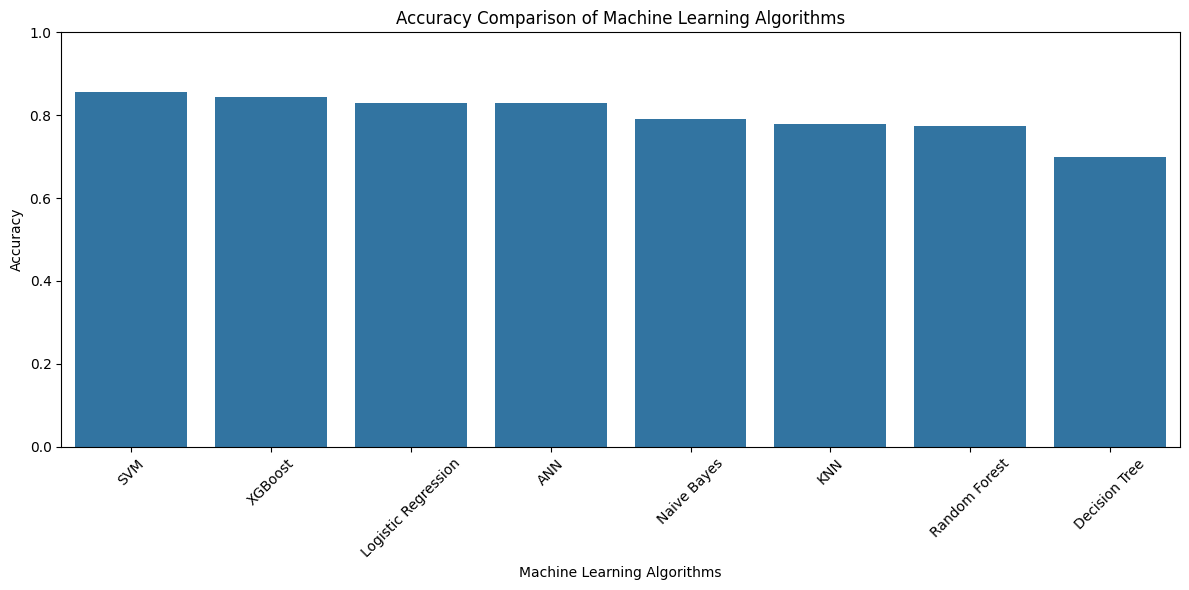

In [96]:
# Algorithm accuracy comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df.sort_values(
        by="Accuracy", ascending=False
    ),
    x="Algorithm",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Machine Learning Algorithms")
plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy")

plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

,Algorithm,F1_Score
4,SVM,0.641411
6,ANN,0.615920
0,Logistic Regression,0.603123
2,Random Forest,0.586262
7,XGBoost,0.559721
5,Naive Bayes,0.481925
3,KNN,0.480884
1,Decision Tree,0.377894


Best Performing Model: SVM


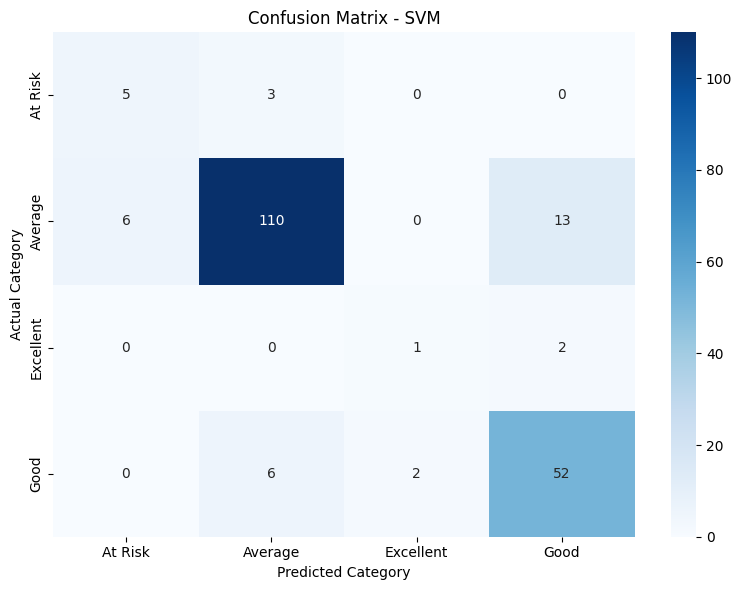

In [111]:
# Identify Best Model Using Macro F1-Score

from sklearn.metrics import f1_score, confusion_matrix

# Calculate Macro F1-score for each model
f1_results = []

for name, model in trained_models.items():

    X_eval = X_test_processed

    if name == "Naive Bayes" and hasattr(X_eval, "toarray"):
        X_eval = X_eval.toarray()

    y_pred = model.predict(X_eval)

    macro_f1 = f1_score(
        y_test_encoded,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_results.append({
        "Algorithm": name,
        "F1_Score": macro_f1
    })

# Create F1-score results DataFrame
f1_results_df = pd.DataFrame(f1_results)

display(
    f1_results_df.sort_values(
        by="F1_Score",
        ascending=False
    )
)

# Identify the best model
best_model_name = f1_results_df.loc[
    f1_results_df["F1_Score"].idxmax(),
    "Algorithm"
]

best_model = trained_models[best_model_name]

print("Best Performing Model:", best_model_name)

# Predict using the best model
X_eval = X_test_processed

if best_model_name == "Naive Bayes" and hasattr(X_eval, "toarray"):
    X_eval = X_eval.toarray()

best_predictions = best_model.predict(X_eval)

# Generate confusion matrix
cm = confusion_matrix(
    y_test_encoded,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()

In [114]:
# Save model comparison results

results_df.to_csv(
    "student_model_evaluation_results.csv",
    index=False
)

print("Evaluation results saved successfully!")

# Save F1-score comparison results

f1_results_df.to_csv(
    "student_model_f1_results.csv",
    index=False
)

print("F1-score results saved successfully!")

Evaluation results saved successfully!
F1-score results saved successfully!


In [115]:
# Save the best trained model
import joblib

joblib.dump(best_model, "best_student_model.pkl")

print("Best model:", best_model_name)
print("Best model saved successfully!")

Best model: SVM
Best model saved successfully!


In [116]:
from google.colab import files

files.download("best_student_model.pkl")
files.download("student_preprocessor.pkl")
files.download("student_label_encoder.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [120]:
import sklearn

print("Google Colab Scikit-learn version:", sklearn.__version__)

Google Colab Scikit-learn version: 1.6.1


In [2]:
from google.colab import files
uploaded = files.upload()



Saving student_performance_dataset.csv to student_performance_dataset.csv


In [3]:
!pip install -q imbalanced-learn xgboost

In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

from imblearn.over_sampling import RandomOverSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load dataset
df = pd.read_csv("student_performance_dataset.csv")

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["Performance_Category"].value_counts())

# 2. Separate features and target
X = df.drop(columns=["Performance_Category", "Student_ID"])
y = df["Performance_Category"]

# 3. Identify numerical and categorical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# 4. Preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# 5. Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 6. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# 7. Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# 8. Oversample training data only
oversampler = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = oversampler.fit_resample(
    X_train_processed,
    y_train
)

# 9. Define eight classifiers
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(),
    "Naive Bayes": GaussianNB(),
    "ANN": MLPClassifier(max_iter=1000, random_state=42),
    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="mlogloss"
    )
}

# 10. Train and evaluate
results = []
trained_models = {}

for name, model in models.items():

    model.fit(X_train_balanced, y_train_balanced)

    predictions = model.predict(X_test_processed)

    trained_models[name] = model

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# Sort by weighted F1
results_df = results_df.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON TABLE")
display(results_df.round(4))

# 11. Select best model
best_model_name = results_df.iloc[0]["Algorithm"]
best_model = trained_models[best_model_name]

print("\nBest model:", best_model_name)

# 12. Classification report
best_predictions = best_model.predict(X_test_processed)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# 13. Confusion matrix
print("\nCONFUSION MATRIX")
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(len(label_encoder.classes_))
)

cm_df = pd.DataFrame(
    cm,
    index=label_encoder.classes_,
    columns=label_encoder.classes_
)

display(cm_df)

# 14. Save evaluation outputs
results_df.to_csv("model_comparison_results.csv", index=False)
cm_df.to_csv("confusion_matrix.csv")

print("\nEvaluation files saved successfully.")


Dataset shape: (1000, 15)

Target distribution:
Performance_Category
Average      644
Good         299
At Risk       41
Excellent     16
Name: count, dtype: int64

MODEL COMPARISON TABLE


,Algorithm,Accuracy,Precision,Recall,Weighted F1
0,SVM,0.840,0.8522,0.840,0.8439
1,ANN,0.840,0.8402,0.840,0.8398
2,Random Forest,0.820,0.8263,0.820,0.8051
3,XGBoost,0.815,0.8118,0.815,0.7992
4,Logistic Regression,0.780,0.8343,0.780,0.7988
5,Naive Bayes,0.680,0.7757,0.680,0.7134
6,Decision Tree,0.685,0.6750,0.685,0.6793
7,KNN,0.650,0.7260,0.650,0.6702



Best model: SVM

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     At Risk       0.45      0.62      0.53         8
     Average       0.92      0.85      0.89       129
   Excellent       0.33      0.33      0.33         3
        Good       0.78      0.87      0.82        60

    accuracy                           0.84       200
   macro avg       0.62      0.67      0.64       200
weighted avg       0.85      0.84      0.84       200


CONFUSION MATRIX


,At Risk,Average,Excellent,Good
At Risk,5,3,0,0
Average,6,110,0,13
Excellent,0,0,1,2
Good,0,6,2,52



Evaluation files saved successfully.
